In [3]:
import os
import operator
from dotenv import load_dotenv
from typing import TypedDict, Literal, Annotated
from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import PromptTemplate
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command

In [4]:
load_dotenv()
generator_api_key = os.getenv("GENERATE_CONTENT_API")
optimizer_api_key = os.getenv("OPTIMIZER_API")
groq_api_key = os.getenv("GROQ_API_KEY")

In [ ]:
from google import genai
import os

client = genai.Client(api_key=os.getenv("OPTIMIZER_API"))

for model in client.models.list():
    print(model.name)

In [ ]:
from groq import Groq
import os

client = Groq(api_key=os.getenv("GROQ_API_KEY"))

models = client.models.list()

for model in models.data:
    print(model.id)

In [5]:
generator_model = ChatGoogleGenerativeAI(model="gemini-3.5-flash",api_key=generator_api_key,temperature=0.3)
evaluator_model = ChatGroq(model="openai/gpt-oss-120b",api_key=groq_api_key,temperature=0.3)
optimizer_model = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite-preview",api_key=optimizer_api_key,temperature=0.3)


In [6]:
from pydantic import BaseModel, Field

class PostEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
    feedback: str = Field(..., description="feedback for the post.")

In [7]:
structured_evaluator_llm = evaluator_model.with_structured_output(PostEvaluation,method="json_mode")

In [8]:
class LinkedInState(TypedDict):
    topic: str
    post: str
    feedback: str
    evaluation: Literal["approved", "needs-improvement"]
    human_approval: Literal["yes","no"]
    approved: bool
    iteration: int
    max_iteration: int

In [9]:
def generate_post(state: LinkedInState):
    prompt = PromptTemplate(
        template = """
        Your are a LinkedIn content writer
        Create a professional LinkedIn post
        Keep the LinkedIn post under 1,500 characters.
        Topic:{topic}
        Requirements:
        - Strong Hook
        - Clear Story
        - Technical learnings
        - Good readability
        - Professional tone
        - Call to action
        - Relevant hashtags
        - Do not use emojis excessively
        - This is version {iteration} + 1

        Return only the LinkedIn post.
        """,
        input_variables = ["topic","iteration"]
    ) 
    final_prompt = prompt.invoke(
            {
                "topic": state["topic"],
                "iteration": state["iteration"]
            }
        ) 
    response = generator_model.invoke(final_prompt).content
    iteration = state["iteration"] + 1
    return{
        "post" : response,
        "iteration": iteration
    }

In [10]:
def evaluate_post(state: LinkedInState):
    prompt = PromptTemplate(
        template="""
        You are a senior LinkedIn reviewer.

        Review the following  linkedIn post.
        Post:{draft}
        Focus on:

        - Stronger hook
        - Better readability
        - Better engagement
        - Grammar
        - Professional tone
        - Technical clarity
        - Max characters less than 1500

        Return ONLY valid JSON.

        The JSON must contain exactly these fields:
        {{
            "evaluation": "approved" or "needs_improvement",
            "feedback": "One paragraph explaining the strengths and weaknesses"
        }}

        Do not include markdown or ```json```. 
        """,
        input_variables = ["draft"]
    )
    final_prompt = prompt.invoke(
        {
            "draft":state["post"]
        }
    )
    response = structured_evaluator_llm.invoke(final_prompt)
    return {
        "evaluation": response.evaluation,
        "feedback": response.feedback
    }

In [11]:
def optimize_post(state: LinkedInState) :
    prompt = PromptTemplate(
    template="""
    You are an expert LinkedIn content optimizer.

    Your task is to improve an existing LinkedIn post based on feedback
    provided by a separate reviewer.
    Keep the final LinkedIn post under 1,500 characters.
    
    REVIEWER FEEDBACK:
    {feedback}
    
    ORIGINAL POST:
    {draft}

    TOPIC / SOURCE INFORMATION:
    {topic}

    Instructions:

    1. Preserve all factual information from the original post.
    2. Do not invent projects, technologies, results, achievements,
    metrics, experiences, or claims that are not present in the
    original post or topic.
    3. Apply the reviewer's feedback carefully.
    4. Improve the hook so that it captures attention naturally.
    5. Improve clarity and readability.
    6. Keep the technical content accurate.
    7. Make the post professional and authentic rather than promotional.
    8. Remove unnecessary repetition and filler.
    9. Keep the post reasonably concise for LinkedIn.
    10. Maintain a natural storytelling flow.
    11. Include a clear but non-pushy call to action when appropriate.
    12. Use relevant hashtags, but do not overuse them.
    13. Do not excessively use emojis.
    14. If the reviewer says the post is already good, make only
        necessary improvements rather than completely rewriting it.

    Return ONLY the final optimized LinkedIn post.
    Do not include analysis, evaluation, explanations, or labels.

    """,
        input_variables=[
            "draft",
            "feedback",
            "topic"
        ]
    )
    final_prompt = prompt.invoke(
        {
            "draft":state["post"],
            "feedback":state["feedback"],
            "topic": state["topic"]
        }
    )
    response = optimizer_model.invoke(final_prompt).content
    iteration = state["iteration"]+1
    return {
        "post": response,
        "iteration":iteration
    }

In [24]:
def route_evaluation(state:LinkedInState) :
    if(state["evaluation"] == "approved" or state["iteration"]>=state["max_iteration"]) :
        print("\n" + "=" * 60)
        print(f"ITERATION {state.get('iteration', 1)}")
        print("=" * 60)

        print(state["post"])

        choice = input("\nPublish this post? (yes/no): ").strip().lower()
        state["human_approval"]:choice

        if (state["human_approval"] == "yes") :
            return "approved"
        else:
            return "needs_improvement"
    else:
        return "needs_improvement"

In [13]:
def human_approval(state: LinkedInState):

    print("\n" + "=" * 60)
    print(f"ITERATION {state.get('iteration', 1)}")
    print("=" * 60)

    print(state["post"])

    choice = input("\nPublish this post? (yes/no): ").strip().lower()
    state["human_approval"] = choice

    if (state["human_approval"] == "yes") :
        return "yes"
    else:
        return "no"

        
     

In [14]:
def publish_post(state: LinkedInState):

    print("Publishing to LinkedIn...")

    return {
        "approved": True
    }

In [28]:
LinkedIn = StateGraph(LinkedInState)

LinkedIn.add_node('generate',generate_post)
LinkedIn.add_node('evaluate',evaluate_post)
LinkedIn.add_node('optimize',optimize_post)
LinkedIn.add_node('publish',publish_post)

In [29]:
LinkedIn.add_edge(START, 'generate')
LinkedIn.add_edge('generate', 'evaluate')
LinkedIn.add_conditional_edges('evaluate', route_evaluation, {"approved": 'publish', "needs_improvement":'optimize'})
LinkedIn.add_edge('optimize','evaluate')
LinkedIn.add_conditional_edges('publish', human_approval, {"yes":END, "no":'optimize'})

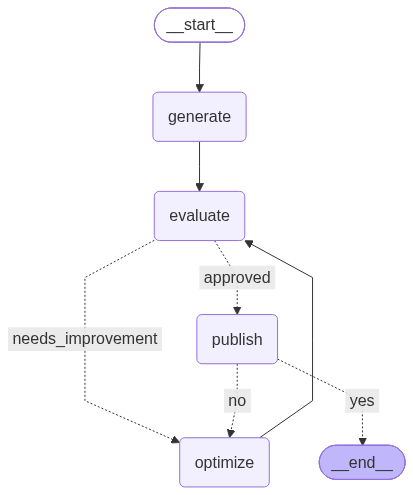

In [30]:
LinkedIn.compile()

In [31]:
app = LinkedIn.compile()

In [32]:
result = app.invoke({
    "topic": """
    Building an AI-powered LinkedIn post automation system using LangGraph,
    Groq, Gemini, and Composio. The system generates a post, uses Gemini
    to review it, iteratively improves it based on feedback, asks for human
    approval, and finally publishes it to LinkedIn.
    """,

    "post": "",
    "feedback": "",
    "evaluation": "needs-improvement",
    "human_approval": "no",
    "approved": False,
    "iteration": 0,
    "max_iteration": 3
})


ITERATION 3
[{'type': 'text', 'text': 'Most AI-generated content fails because it lacks a pulse. To bridge the gap between automation and authenticity, I built an agentic pipeline that treats AI as a draft engine and a human as the final architect.\n\nI moved beyond simple, single-prompt generation to create a system that ensures quality at every step:\n\n1. **Generation:** Groq creates the initial draft for speed and structure.\n2. **Critique:** Gemini reviews the draft against specific brand and tone guidelines.\n3. **Refinement:** The system iteratively improves the content based on that feedback.\n4. **Human-in-the-Loop:** LangGraph pauses the workflow, waiting for my manual approval.\n5. **Publishing:** Composio handles the secure API integration to post directly.\n\n**Key Technical Takeaways:**\n\n* **Stateful Orchestration:** LangGraph’s ability to pause and resume state is essential for Human-in-the-Loop (HITL) workflows. It ensures the AI never publishes without a final human

KeyboardInterrupt: 